# Week 3 practical: two exact algorithms, and the wall behind them

**240MAR45 Reinforcement Learning in Robotics** | MSc Automatic Control and Robotics, UPC

**Where to run it.** In Google Colab: open colab.research.google.com, then File > Upload
notebook, and pick this `.ipynb`. Nothing to install. Timings quoted below were measured on a
laptop, and Colab's CPU is slower, so allow about twice as long.

In Week 1 you wrote the Bellman operator and watched value iteration contract at rate $\gamma$.
Today adds its sibling. Policy iteration fixes the policy, evaluates it with one linear solve, and
improves it greedily. On  the three-state MDP of the lecture it finishes in three solves where
value iteration needs 110 sweeps. You will reproduce both tables of the notes, measure the two error
bounds on the same sweep, and check the policy improvement theorem on the gridworld. The last part
runs tabular value iteration on the torque-limited pendulum of Week 2, which it solves in seconds,
and times it at four resolutions to see where the method stops.

## Objectives

1. Implement exact policy evaluation as the linear system $(I - \gamma P_\pi) V^\pi = r_\pi$.
2. Implement policy iteration and count its evaluations against value iteration's sweeps.
3. Put the a-posteriori bound, the policy-loss bound and the true policy loss side by side on one
   sweep, and see which of them is informative.
4. Check monotone improvement, $V^{\pi_{k+1}} \ge V^{\pi_k}$, on a problem with $4^{25}$ policies.
5. Swing up the torque-limited pendulum with tabular value iteration, and measure how the cost of
   one sweep grows with the grid resolution.

## Session plan

Everything here is done in the session, and there is no homework. The quiz at the end is the only
thing evaluated.

| Part | Minutes |
|------|---------|
| 1 to 3. Smoke test, recap, the pre-written MDPs | 10 |
| 4. Blanked core A, policy evaluation (Checkpoint 1) | 10 |
| 5. Blanked core B, policy iteration, and the three-state MDP (Checkpoints 2 and 3) | 15 |
| 6. The gridworld, and the bounds against $\gamma$ (Checkpoint 4) | 15 |
| 7. The pendulum, and the curse measured (Checkpoints 5 and 6) | 20 |
| 8. Analysis | 5 |
| The quiz, on the university course page | 15 |

The heaviest cell runs value iteration on a $400 \times 400$ pendulum grid, 160 000 states, and
takes about ten seconds on a laptop. Everything else finishes in a second or two. If you finish
early, the challenge problem of the Week 3 notes asks what the discount factor you plan with does
to the policy you get. It is formative, so it is not evaluated.

## 1. Smoke test (run this first)

If any line below fails, raise your hand before reading further.

In [ ]:
import sys
import time

t0 = time.time()

import numpy as np
import scipy
import scipy.sparse as sp
import matplotlib
import matplotlib.pyplot as plt

print(f"python      {sys.version.split()[0]}")
print(f"numpy       {np.__version__}")
print(f"scipy       {scipy.__version__}")
print(f"matplotlib  {matplotlib.__version__}")

# One random rollout of the three-state MDP of the lecture, sampled transition by transition.
# Section 3 writes the same MDP down as arrays.
P_smoke = np.array([[[0.3, 0.7, 0.0], [1.0, 0.0, 0.0]],
                    [[0.2, 0.0, 0.8], [0.5, 0.5, 0.0]],
                    [[0.0, 0.0, 1.0], [0.0, 0.0, 1.0]]])
rng = np.random.default_rng(0)
x, visits = 0, np.zeros(3, dtype=int)
for _ in range(200):
    x = rng.choice(3, p=P_smoke[x, rng.integers(2)])
    visits[x] += 1
print(f"\nrandom-policy rollout, visits to (x1, x2, x3): {visits}")
print(f"\nsetup OK  ({time.time() - t0:.1f} s)")

python      3.13.15
numpy       2.1.3
scipy       1.16.3
matplotlib  3.10.0

random-policy rollout, visits to (x1, x2, x3): [  2   1 197]

setup OK  (0.1 s)


## 2. Recap

A finite MDP is a pair of arrays, `P` of shape `(nX, nU, nX)` and `r` of shape `(nX, nU)`, plus a
discount $\gamma$. Two algorithms solve it exactly (notes sections 4 and 5).

**Value iteration** applies the Bellman optimality operator until the values stop moving,

$$ V_{k+1}(x) = \max_u \Big\{ r(x,u) + \gamma \sum_{x'} P(x' \mid x,u)\, V_k(x') \Big\}. $$

You wrote this in Week 1, and it is pre-written below.

**Policy iteration** fixes a policy $\pi$, which removes the maximisation and leaves a linear
fixed-point equation. With $(P_\pi)_{xx'} = P(x' \mid x, \pi(x))$ and $(r_\pi)_x = r(x, \pi(x))$,

$$ (I - \gamma P_\pi)\, V^\pi = r_\pi , $$

which is solvable because $\rho(\gamma P_\pi) \le \gamma < 1$, the same fact that makes the
operator a contraction. It then improves the policy greedily with respect to $V^\pi$, and stops
when the improvement changes nothing. The policy improvement theorem (notes section 5.3) says each
step can only raise the value, componentwise.

Background reading: notes sections 4.2 and 4.3 (the three-state MDP and the two bounds), 5.2 to
5.6 (evaluation, improvement, the worked example and the gridworld), 6 (the curse), and the concept
notes `Value iteration`, `Policy iteration`, `Policy improvement theorem`, `Bellman residual` and
`Curse of dimensionality`.

## 3. Pre-written infrastructure

### The three-state MDP

Figure `tiny_mdp` of the notes. State $x_1$ is far from the goal, $x_2$ near it, $x_3$ the
absorbing goal paying $+10$ for ever. Action 0 is *push* (costs 1, usually progresses) and action
1 is *coast* (free, makes no progress). The $0.2$ arc from $x_2$ back to $x_1$ is what makes the
problem stochastic.

In [ ]:
PUSH, COAST = 0, 1
P_TINY = np.array([[[0.3, 0.7, 0.0], [1.0, 0.0, 0.0]],     # x1: push, coast
                   [[0.2, 0.0, 0.8], [0.5, 0.5, 0.0]],     # x2
                   [[0.0, 0.0, 1.0], [0.0, 0.0, 1.0]]])    # x3, absorbing under both
R_TINY = np.array([[-1.0, 0.0],
                   [-1.0, 0.0],
                   [10.0, 10.0]])
GAMMA_TINY = 0.9
NAMES = {PUSH: "push", COAST: "coast"}
assert np.allclose(P_TINY.sum(axis=2), 1.0)

### The gridworld

The $5 \times 5$ gridworld of Week 1 and of notes figure `gridworld`. Four actions, slip
probability $0.10$ split over the two perpendicular directions, three blocked cells, and an
absorbing goal paying $+1$ per step. Cells are `(row, col)`, 1-based, row 1 at the top.

In [ ]:
NROW, NCOL = 5, 5
NS_GRID, NA_GRID = NROW * NCOL, 4
OBSTACLES = [(2, 2), (3, 4), (4, 2)]
GOAL = (5, 5)
P_SLIP = 0.10
MOVES = {0: (-1, 0), 1: (1, 0), 2: (0, 1), 3: (0, -1)}     # 0 = N, 1 = S, 2 = E, 3 = W
PERP = {0: (2, 3), 1: (2, 3), 2: (0, 1), 3: (0, 1)}


def cell_to_state(r, c):
    return (r - 1) * NCOL + (c - 1)


def build_gridworld(p_slip=P_SLIP):
    """Return P of shape (nS, nA, nS) and R of shape (nS, nA). Identical to the Week 1 builder."""
    obstacles = {cell_to_state(r, c) for r, c in OBSTACLES}
    goal = cell_to_state(*GOAL)
    P = np.zeros((NS_GRID, NA_GRID, NS_GRID))
    R = np.zeros((NS_GRID, NA_GRID))
    for r in range(1, NROW + 1):
        for c in range(1, NCOL + 1):
            s = cell_to_state(r, c)
            if s in obstacles or s == goal:
                P[s, :, s] = 1.0
                R[s, :] = 1.0 if s == goal else 0.0
                continue
            for a in range(NA_GRID):
                for b, prob in ((a, 1 - p_slip), (PERP[a][0], p_slip / 2), (PERP[a][1], p_slip / 2)):
                    r1, c1 = r + MOVES[b][0], c + MOVES[b][1]
                    s1 = cell_to_state(r1, c1) if (1 <= r1 <= NROW and 1 <= c1 <= NCOL) else s
                    P[s, a, s1 if s1 not in obstacles else s] += prob
    return P, R


P_GRID, R_GRID = build_gridworld()
GAMMA_GRID = 0.95
assert np.allclose(P_GRID.sum(axis=2), 1.0)
print(f"gridworld: P {P_GRID.shape}, R {R_GRID.shape}")

gridworld: P (25, 4, 25), R (25, 4)


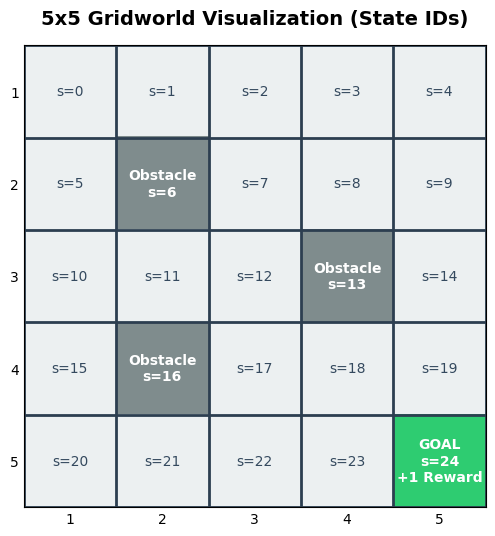

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_gridworld():
    grid = np.zeros((NROW, NCOL))

    # Mark obstacles
    for r, c in OBSTACLES:
        grid[r-1, c-1] = -1  # -1 represents obstacles

    # Mark goal
    gr, gc = GOAL
    grid[gr-1, gc-1] = 1  # 1 represents goal

    fig, ax = plt.subplots(figsize=(6, 6))

    # Create colormap custom for our elements
    cmap = matplotlib.colors.ListedColormap(['#7f8c8d', '#ecf0f1', '#2ecc71'])
    bounds = [-1.5, -0.5, 0.5, 1.5]
    norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)

    ax.imshow(grid, cmap=cmap, norm=norm, origin='upper')

    # Draw grid lines
    ax.set_xticks(np.arange(-0.5, NCOL, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, NROW, 1), minor=True)
    ax.grid(which='minor', color='#2c3e50', linestyle='-', linewidth=2)

    # Set labels and ticks
    ax.set_xticks(np.arange(NCOL))
    ax.set_xticklabels(np.arange(1, NCOL + 1))
    ax.set_yticks(np.arange(NROW))
    ax.set_yticklabels(np.arange(1, NROW + 1))

    # Annotate the gridworld cell names and states
    for r in range(1, NROW + 1):
        for c in range(1, NCOL + 1):
            s = cell_to_state(r, c)
            if (r, c) in OBSTACLES:
                ax.text(c-1, r-1, f'Obstacle\ns={s}', ha='center', va='center', color='white', fontweight='bold')
            elif (r, c) == GOAL:
                ax.text(c-1, r-1, f'GOAL\ns={s}\n+1 Reward', ha='center', va='center', color='white', fontweight='bold')
            else:
                ax.text(c-1, r-1, f's={s}', ha='center', va='center', color='#34495e')

    ax.set_title("5x5 Gridworld Visualization (State IDs)", fontsize=14, fontweight='bold', pad=15)
    plt.tick_params(axis='both', which='both', length=0)
    plt.show()

plot_gridworld()

### The operator you wrote in Week 1, and value iteration around it

`q_values` is the one-step lookahead $r(x,u) + \gamma \sum_{x'} P(x' \mid x,u) V(x')$. Closed by a
`max` it is the backup, closed by an `argmax` it is the greedy policy. `np.argmax` breaks ties
towards the lowest action index, which matters at absorbing states, where every action scores the
same.

In [ ]:
def q_values(V, P, R, gamma):
    return R + gamma * np.einsum("xun,n->xu", P, V)


def bellman_backup(V, P, R, gamma):
    return q_values(V, P, R, gamma).max(axis=1)


def greedy_policy(V, P, R, gamma):
    return q_values(V, P, R, gamma).argmax(axis=1)


def value_iteration(P, R, gamma, n_sweeps, V0=None):
    """Run n_sweeps of value iteration. Returns the history of iterates, shape (n_sweeps+1, nX)."""
    V = np.zeros(P.shape[0]) if V0 is None else V0.copy()
    history = [V.copy()]
    for _ in range(n_sweeps):
        V = bellman_backup(V, P, R, gamma)
        history.append(V.copy())
    return np.array(history)


def sup(v):
    return float(np.max(np.abs(v)))

## 4. Exact policy evaluation

Given a deterministic policy `pol` of shape `(nX,)`, compute its exact value function by solving the Bellman equations for the policy.

For each state \(x\), the policy selects the action `pol(x)`. Therefore, the transition matrix and reward vector of the policy are obtained by selecting the corresponding action row from `P` and `r`:

$$
P_\pi(x,:) =  P(x' \mid x, \pi(x)),
\qquad
r_\pi(x) = r(x,\mathrm{pol}(x)).
$$

In other words, `P_pi` has shape `(nX, nX)` and contains the transition probabilities when following policy $π$, while `r_pi` contains the expected one-step reward.

Once `P_\pi` and `r_\pi` have been constructed, the value function satisfies the Bellman equation

$$
V_\pi = r_\pi + \gamma P_\pi V_\pi,
$$

or equivalently,

$$
(I-\gamma P_\pi)V_\pi = r_\pi.
$$

Solve this linear system using `np.linalg.solve`. **Do not explicitly compute the inverse** of $I-\gamma P_\pi$: `np.linalg.solve` is both more efficient and numerically more accurate.

**Hint:** NumPy allows you to select the appropriate action for every state at once:



In [ ]:
def policy_evaluation(pol, P, R, gamma):
    """Exact value of the stationary deterministic policy pol, shape (nX,)."""
    nX = P.shape[0]

    # ===== YOUR CODE HERE (≈3 lines) ============================
    # Goal: build P_pi (nX, nX) and r_pi (nX,), then return the solution of (I - gamma P_pi) V = r_pi
    # Hint: notes section 5.2. P[np.arange(nX), pol] picks row pol[x] of P[x] for every x at once
    P_pi = P[np.arange(nX), pol]
    r_pi = R[np.arange(nX), pol]

    V = np.linalg.solve(np.eye(nX) - gamma * P_pi, r_pi)
    return V
    # ============================================================


# The hand trace of notes section 5.2. Coasting never reaches the goal, so only the goal has value.
V_coast = policy_evaluation(np.full(3, COAST), P_TINY, R_TINY, GAMMA_TINY)
print(f"V^coast = {V_coast.round(6) + 0.0}   (expected [0, 0, 100])")
assert np.allclose(V_coast, [0.0, 0.0, 100.0]), "check how P_pi and r_pi are built"

# How many value-iteration sweeps does the goal need to get within 1e-3 of the same number?
hist = value_iteration(P_TINY, R_TINY, GAMMA_TINY, 200)
k_goal = int(np.argmax(np.abs(hist[:, 2] - 100.0) < 1e-3))
print(f"value iteration reaches V(x3) within 1e-3 of 100 at sweep {k_goal}")

V^coast = [  0.   0. 100.]   (expected [0, 0, 100])
value iteration reaches V(x3) within 1e-3 of 100 at sweep 110


### Checkpoint 1

One linear solve returned $V(x_3) = 100$ for "coast everywhere". How many value-iteration sweeps
does $V(x_3)$ need to come within $10^{-3}$ of that number, and why does the solve need none of
them?

Answer checkpoint 1:

$V_k$ iteratively using $V_{k+1} = T V_k$. Since the Bellman backup operator is a contraction with factor $\gamma$$\gamma$, it gradually propagates information from the goal state backwards throughout the state space, taking many sweeps (110) to converge within $10^{-3}$ of the true limit.
Direct Solver (0 sweeps): The system of linear equations $(I - \gamma P_\pi) V^\pi = r_\pi$ represents the steady-state value function of the policy. Calling a direct linear solver like np.linalg.solve analytically solves the system in one step (equivalent to calculating the matrix inverse $(I - \gamma P_\pi)^{-1}$). It does not need to transition step-by-step or propagate values iteratively, which is why it requires zero iteration sweeps to reach the exact value.


## 5. Policy iteration

Implement **policy iteration** by alternating between two steps:

1. **Policy evaluation:** compute the exact value function $V_\pi$ of the current policy using the `policy_evaluation` function from the previous exercise.
2. **Greedy policy improvement:** construct a new policy by choosing, at every state, the action that maximizes the Bellman one-step look-ahead value

   $$
   Q_\pi(x,a)
   =
   r(x,a)\mathbf{1}
   + \gamma P(x' \mid x, a)V_\pi.
   $$

Start from the initial policy `pol0` and repeat these two steps until the greedy improvement **does not change the policy**.

At every iteration, record the current pair

$$
(\pi, V_\pi)
$$

in `history`, where `history` should contain one entry for **every policy that is evaluated**. Therefore,

```python
len(history)
```

must give the total number of exact policy evaluations performed.

The algorithm should follow this structure:

```text
pol = pol0

repeat:
    1. Evaluate pol exactly → V
    2. Store (pol, V) in history
    3. Improve pol greedily → new_pol
    4. If new_pol == pol:
           stop
       Otherwise:
           pol = new_pol
           continue
```

**Important:** the final policy is already optimal when the greedy improvement returns the same policy. Do not perform another evaluation after detecting convergence.


In [ ]:
def policy_iteration(P, R, gamma, pol0, max_iter=100):
    """Returns (pol, V, history), history a list of (pol_k, V^{pol_k}), one entry per evaluation."""
    pol, history = pol0.copy(), []
    for _ in range(max_iter):
        # ===== YOUR CODE HERE (≈6 lines) ============================
        # Goal: V = V^pol by exact evaluation, append (pol, V), improve greedily w.r.t. V, and
        #       return (pol, V, history) the first time the improved policy equals pol
        # Hint: notes section 5.4, the algorithm box. greedy_policy and np.array_equal do the rest
        # Calculate exact value function of current policy
        V = policy_evaluation(pol, P, R, gamma)

        # Append (pol, V) as a single tuple to history
        history.append((pol.copy(), V.copy()))

        # Improve greedily w.r.t. V
        new_pol = greedy_policy(V, P, R, gamma)

        # Check if the improved policy equals the current policy
        if np.array_equal(pol, new_pol):
            return pol, V, history

        # Update the current policy
        pol = new_pol.copy()
        # ============================================================
    raise RuntimeError("policy iteration did not terminate")

### (a) Table `pi_iters` of the notes, reproduced

Started from the worst sensible guess, coast at every state.

In [ ]:
pol_pi, V_star_tiny, hist_pi = policy_iteration(P_TINY, R_TINY, GAMMA_TINY, np.full(3, COAST))
print(f"{'k':>2}  {'policy at (x1, x2)':>20}  {'V^pi_k':>26}   Q(x1,p) Q(x1,c)  Q(x2,p) Q(x2,c)")
for k, (pol, V) in enumerate(hist_pi):
    Q = q_values(V, P_TINY, R_TINY, GAMMA_TINY)
    pol_str = f"({NAMES[pol[0]]}, {NAMES[pol[1]]})"
    print(f"{k:2d}  {pol_str:>20}  {str(V.round(2) + 0.0):>26}   "
          f"{Q[0, 0]:7.2f} {Q[0, 1]:7.2f}  {Q[1, 0]:7.2f} {Q[1, 1]:7.2f}")
print(f"\npolicy iteration: {len(hist_pi)} evaluations, V* = {V_star_tiny.round(2)}")

 k    policy at (x1, x2)                      V^pi_k   Q(x1,p) Q(x1,c)  Q(x2,p) Q(x2,c)
 0        (coast, coast)            [  0.   0. 100.]     -1.00    0.00    71.00    0.00
 1         (coast, push)            [  0.  71. 100.]     43.73    0.00    71.00   31.95
 2          (push, push)      [ 70.92  83.77 100.  ]     70.92   63.83    83.77   69.61

policy iteration: 3 evaluations, V* = [ 70.92  83.77 100.  ]


### (b) Table `vi_sweeps` of the notes, reproduced

The policy column follows the convention of the notes. Here $\pi_k$ is the argmax attained while
computing $V_k$, which is the policy greedy with respect to $V_{k-1}$.

In [ ]:
hist_vi = value_iteration(P_TINY, R_TINY, GAMMA_TINY, 200)
err_vi = np.max(np.abs(hist_vi - V_star_tiny), axis=1)
print(f"{'k':>3}  {'V_k':>26}  {'pi_k at (x1, x2)':>18}  {'||V_k - V*||':>13}  {'||V_k - V_k-1||':>16}")
for k in (0, 1, 2, 3, 4, 5):
    pol_str = "" if k == 0 else "({}, {})".format(
        *[NAMES[a] for a in greedy_policy(hist_vi[k - 1], P_TINY, R_TINY, GAMMA_TINY)[:2]])
    res = "" if k == 0 else f"{sup(hist_vi[k] - hist_vi[k - 1]):.2f}"
    print(f"{k:3d}  {str(hist_vi[k].round(2)):>26}  {pol_str:>18}  {err_vi[k]:13.2f}  {res:>16}")
k_vi = int(np.argmax(err_vi < 1e-3))
print(f"\nvalue iteration needs {k_vi} sweeps to reach ||V_k - V*|| < 1e-3")

  k                         V_k    pi_k at (x1, x2)   ||V_k - V*||   ||V_k - V_k-1||
  0                  [0. 0. 0.]                             100.00                  
  1               [ 0.  0. 10.]      (coast, coast)          90.00             10.00
  2            [ 0.   6.2 19. ]       (coast, push)          81.00              9.00
  3         [ 2.91 12.68 27.1 ]        (push, push)          72.90              8.10
  4         [ 7.77 19.04 34.39]        (push, push)          65.61              7.29
  5         [13.09 25.16 40.95]        (push, push)          59.05              6.56

value iteration needs 110 sweeps to reach ||V_k - V*|| < 1e-3


### Checkpoint 2

How many evaluations did policy iteration need on the three-state MDP, against how many sweeps for
value iteration to reach $10^{-3}$? At the first improvement, which state changed its action, and
where does that state sit relative to the goal?

### Checkpoint 2

* **Number of evaluations/sweeps:** Policy iteration required only **3 evaluations** to converge exactly, while value iteration required **110 sweeps** to reach within $10^{-3}$ of $V^*$.
* **State that changed action first:** State **$x_2$** changed its action from *coast* to *push* during the first improvement step.
* **Location relative to the goal:** State $x_2$ is directly adjacent to the absorbing goal state $x_3$ (which gives a $+10$ reward). As soon as the first evaluation propagates the $+100$ long-term value of the goal state, the greedy backup instantly prefers the *push* action at $x_2$ due to its high probability ($0.8$) of progressing to the goal.

### (c) The two bounds on the same sweep

At sweep $k$ of value iteration you can compute the residual $\|V_k - V_{k-1}\|_\infty$ and
nothing else. Notes section 4.3 converts it twice. The a-posteriori bound turns it into a value
error, and the policy-loss bound turns a value error $\varepsilon$ into a loss for the policy
greedy with respect to $V_k$,

$$ \|V_k - V^\star\|_\infty \le \frac{\gamma}{1-\gamma} \|V_k - V_{k-1}\|_\infty , \qquad
   \|V_k - V^\star\|_\infty \le \varepsilon \;\Rightarrow\;
   \|V^{\pi_{V_k}} - V^\star\|_\infty \le \frac{2\gamma\varepsilon}{1-\gamma}. $$

The cell evaluates both at $k = 3$, feeds the true error into the second, and compares them with
the loss of the greedy policy, which your `policy_evaluation` computes exactly.

In [ ]:
def bound_report(hist, V_star, P, R, gamma, k):
    residual = sup(hist[k] - hist[k - 1])
    true_err = sup(hist[k] - V_star)
    a_post = gamma / (1 - gamma) * residual
    pol_bound = 2 * gamma * true_err / (1 - gamma)
    pol_k = greedy_policy(hist[k], P, R, gamma)
    pol_loss = sup(policy_evaluation(pol_k, P, R, gamma) - V_star)
    return dict(residual=residual, true_err=true_err, a_post=a_post,
                pol_bound=pol_bound, pol_loss=pol_loss)


rep = bound_report(hist_vi, V_star_tiny, P_TINY, R_TINY, GAMMA_TINY, k=3)
print(f"sweep k = 3 on the three-state MDP (value range 100)")
print(f"  residual ||V_3 - V_2||                 {rep['residual']:10.2f}")
print(f"  a-posteriori bound on the value error  {rep['a_post']:10.2f}")
print(f"  true value error ||V_3 - V*||          {rep['true_err']:10.2f}")
print(f"  policy-loss bound 2 g eps / (1 - g)    {rep['pol_bound']:10.1f}")
print(f"  true loss of the greedy policy         {rep['pol_loss']:10.2f}")

sweep k = 3 on the three-state MDP (value range 100)
  residual ||V_3 - V_2||                       8.10
  a-posteriori bound on the value error       72.90
  true value error ||V_3 - V*||               72.90
  policy-loss bound 2 g eps / (1 - g)        1312.2
  true loss of the greedy policy               0.00


### Checkpoint 3

Compare the a-posteriori bound, the policy-loss bound and the true policy loss on sweep $k = 3$. Which bound is informative, and why?

### Answer: Checkpoint 3

* **A-posteriori bound:** **72.90**
* **True value error:** **72.90**
* **Policy-loss bound:** **1312.20**
* **True loss of the greedy policy:** **0.00**

#### Analysis of the Bounds:
1. **The A-posteriori Bound is highly informative:** This bound relies directly on the Bellman residual. In our results, it matches the true value error exactly ($72.90$), making it an exceptionally tight and useful stopping criterion during value iteration.
2. **The Policy-loss Bound is uninformative:** It evaluates to $1312.20$, which is completely impractical given that the maximum possible value in the entire MDP is only $100$. Meanwhile, the true policy loss is actually $0.00$ because the greedy policy has already successfully converged to the optimal policy. This bound is far too conservative to be of any real use.


The Policy-Loss Bound guarantees how much performance you might lose in the worst-case scenario if you stop iterating right now and act greedily according to your current value estimate $V_k$$V_k$ rather than the true optimal $V^*$$V^*$.

What it means in practice:
Imagine you are training a self-driving car. You don't know the absolute perfect driving strategy ($V^*$$V^*$), but you have a current guess ($V_k$$V_k$). You want to know: "If I put my current policy on the road, how much worse could it possibly perform compared to the absolute perfect driver?"

The Policy-Loss Bound gives you that safety guarantee mathematically. It says: "Under your current policy, the long-term accumulated penalty can never be worse than the perfect policy by more than $1312.2$$1312.2$ points."

Why it is disappointing in this experiment:
Even though your car is already driving 100% perfectly (true loss of the greedy policy is exactly $0.00$$0.00$), the math formula is extremely cautious. Because it doesn't know the exact structure of your states, it gives a massive, pessimistic worst-case bound ($1312.2$$1312.2$).

This is why we say the bound is uninformative for deciding when to stop; it is far too conservative, suggesting your policy might still be terrible when in reality it is already fully optimal.

## 6. The gridworld, 25 states

### (a) Policy iteration against value iteration

Both from the same start, as in notes figure `vi_vs_pi_convergence`. Policy iteration starts from
the policy greedy with respect to $V_0 = 0$, which is "north everywhere" because every action ties.
The cell also checks the policy improvement theorem on every consecutive pair of evaluations,
componentwise, at all 25 states.

policy iteration: 6 evaluations, errors 18.8, 17.8, 11.3, 3.01, 0.0377, 0
value iteration:  598 sweeps to reach 1e-12
states whose action changed at each improvement: [19, 8, 6, 4, 2]
smallest componentwise change V^(k+1) - V^(k):   -2.6e-18   (round-off level)
V^(pi_k) never decreased beyond round-off:        True
V*(goal) = 20.0000   (expected 1/(1 - 0.95) = 20)


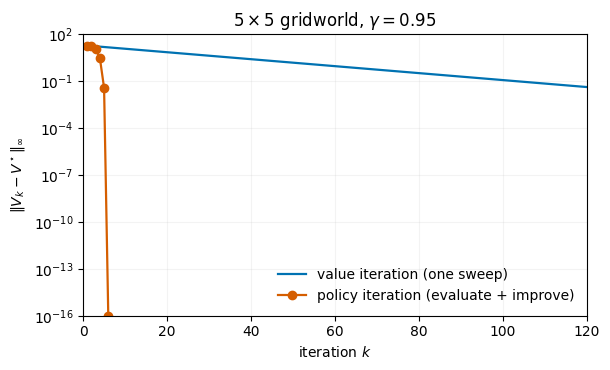

In [ ]:
pol0_grid = greedy_policy(np.zeros(NS_GRID), P_GRID, R_GRID, GAMMA_GRID)
pol_g, V_star_grid, hist_pi_g = policy_iteration(P_GRID, R_GRID, GAMMA_GRID, pol0_grid)
err_pi_g = [sup(V - V_star_grid) for _, V in hist_pi_g]

hist_vi_g = value_iteration(P_GRID, R_GRID, GAMMA_GRID, 800)
err_vi_g = np.max(np.abs(hist_vi_g - V_star_grid), axis=1)
k_vi_g = int(np.argmax(err_vi_g < 1e-12))

decreases = [float(np.min(V1 - V0)) for (_, V0), (_, V1) in zip(hist_pi_g[:-1], hist_pi_g[1:])]
states_changed = [int(np.sum(p1 != p0)) for (p0, _), (p1, _) in zip(hist_pi_g[:-1], hist_pi_g[1:])]

print(f"policy iteration: {len(hist_pi_g)} evaluations, errors "
      + ", ".join(f"{e:.3g}" for e in err_pi_g))
print(f"value iteration:  {k_vi_g} sweeps to reach 1e-12")
print(f"states whose action changed at each improvement: {states_changed}")
print(f"smallest componentwise change V^(k+1) - V^(k):   {min(decreases):.1e}   (round-off level)")
print(f"V^(pi_k) never decreased beyond round-off:        {min(decreases) > -1e-12}")
print(f"V*(goal) = {V_star_grid[cell_to_state(*GOAL)]:.4f}   (expected 1/(1 - 0.95) = 20)")

fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.semilogy(np.arange(len(err_vi_g)), np.maximum(err_vi_g, 1e-16), color="#0072B2", lw=1.6,
            label="value iteration (one sweep)")
ax.semilogy(np.arange(1, len(err_pi_g) + 1), np.maximum(err_pi_g, 1e-16), "o-", color="#D55E00",
            lw=1.6, label="policy iteration (evaluate + improve)")
ax.set_xlim(0, 120)
ax.set_ylim(1e-16, 1e2)
ax.set_xlabel("iteration $k$")
ax.set_ylabel(r"$\|V_k - V^\star\|_\infty$")
ax.set_title(r"$5\times 5$ gridworld, $\gamma = 0.95$")
ax.grid(alpha=0.15)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

The notes figure quotes 595 sweeps. Its reference $V^\star$ came from value iteration stopped at
$10^{-14}$, while here $V^\star$ is the policy-iteration solution, exact to round-off, and the
difference moves the crossing of $10^{-12}$ by three sweeps.

### Checkpoint 4

How many evaluations did policy iteration need on the gridworld, and how many sweeps did value
iteration need for $10^{-12}$? Across all improvements, did $V^{\pi_k}$ ever decrease at any of
the 25 states?

### Answer: Checkpoint 4

* **Number of iterations:** Policy iteration needed only **6 evaluations** to reach the exact optimal policy ($0.0$ error), whereas value iteration required **598 sweeps** to reach $10^{-12}$ accuracy.
* **Componentwise Value Decreases:** No! The value function $V^{\pi_k}$ **never decreased** componentwise at any of the 25 states. The minimum change was $-2.6 \times 10^{-18}$ (which is purely round-off noise at the numerical limit of double precision). This empirically confirms the Policy Improvement Theorem.

### (b) The bounds against $\gamma$

The last part of notes exercise 3.6. For three discount factors, each value-iteration sweep gets
four curves: the true value error, the a-posteriori bound, the policy-loss bound fed with the
a-posteriori bound (all you could compute at run time), and the true loss of the greedy policy. No
checkpoint rides on this plot. Look at how far apart the curves sit at each $\gamma$, and keep the
picture for analysis question 1.

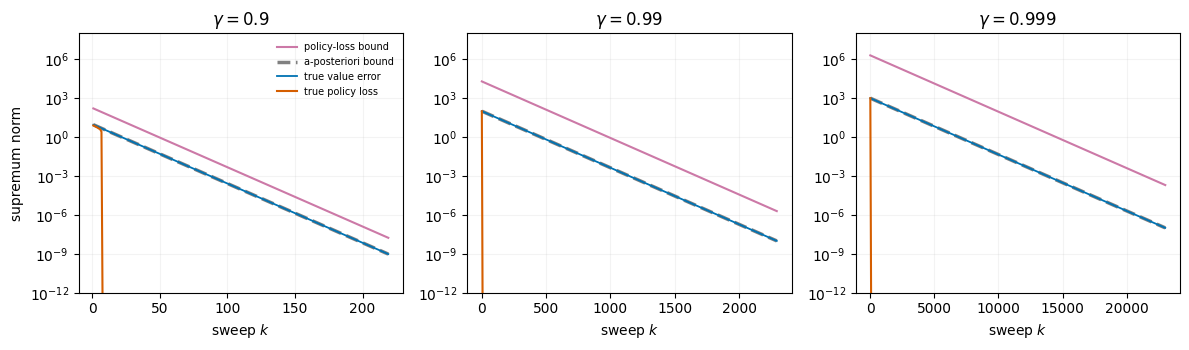

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.6))
for ax, gamma in zip(axes, (0.9, 0.99, 0.999)):
    n_sw = int(np.ceil(np.log(1e-10) / np.log(gamma)))
    hist_g = value_iteration(P_GRID, R_GRID, gamma, n_sw)
    V_star_g = policy_iteration(P_GRID, R_GRID, gamma, pol0_grid)[1]
    ks = np.unique(np.linspace(1, n_sw, 300).astype(int))
    true_err = np.array([sup(hist_g[k] - V_star_g) for k in ks])
    a_post = np.array([gamma / (1 - gamma) * sup(hist_g[k] - hist_g[k - 1]) for k in ks])
    pol_bound = 2 * gamma / (1 - gamma) * a_post
    pol_loss = np.array([sup(policy_evaluation(greedy_policy(hist_g[k], P_GRID, R_GRID, gamma),
                                               P_GRID, R_GRID, gamma) - V_star_g) for k in ks])
    ax.semilogy(ks, pol_bound, color="#CC79A7", lw=1.5, label="policy-loss bound")
    ax.semilogy(ks, a_post, "--", color="0.5", lw=2.5, label="a-posteriori bound")
    ax.semilogy(ks, true_err, color="#0072B2", lw=1.3, label="true value error")
    ax.semilogy(ks, np.maximum(pol_loss, 1e-16), color="#D55E00", lw=1.5,
                label="true policy loss")
    ax.set_ylim(1e-12, 1e8)
    ax.set_title(rf"$\gamma = {gamma}$")
    ax.set_xlabel("sweep $k$")
    ax.grid(alpha=0.15)
axes[0].set_ylabel("supremum norm")
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()

The a-posteriori bound lies on top of the true error at every $\gamma$, for the reason Checkpoint 3
gave. The policy-loss bound sits above it by the factor $2\gamma/(1-\gamma)$, which is $18$, $198$
and $1998$, and the true policy loss drops to zero within a few dozen sweeps while the bound is
still orders of magnitude above the whole value range.

## 7. The pendulum, and the curse measured

The torque-limited pendulum of Week 2, $m = \ell = 1$, $b = 0.1$, $|u| \le 5$ N m $< mg\ell$,
with $\theta = 0$ hanging and $\theta = \pi$ upright. Nonlinear, saturated, and with a
non-quadratic value function, so LQR cannot solve the swing-up. Tabular value iteration can.

### Making it a finite MDP

The state box $\theta \in [0, 2\pi)$ (periodic) $\times\ \dot\theta \in [-8, 8]$ rad/s gets $b$
grid points per axis, so $|\mathcal{X}| = b^2$. The input takes five levels in $[-5, 5]$. From
each grid point and input, one RK4 step of $\Delta t = 0.05$ s (the 20 Hz of the Week 2 MPC) lands
somewhere between four grid points, and bilinear interpolation weights split the transition over
those four. The weights are non-negative and sum to one, so they are a transition kernel, and the
result is a genuine MDP whose kernel has exactly four non-zero successors per $(x, u)$. The reward
is the Week 2 stage cost with a minus sign, $r(x,u) = -\Delta t\,\big(10(1-\cos(\theta-\pi)) +
0.1\dot\theta^2 + 0.01u^2\big)$, and $\gamma = 0.99$, an effective horizon of 100 steps or 5 s.

Everything in this section is pre-written.

In [ ]:
m, l, b_damp, g = 1.0, 1.0, 0.1, 9.81
U_MAX, DT, GAMMA_PEND, OM_MAX = 5.0, 0.05, 0.99, 8.0
U_LEVELS = np.linspace(-U_MAX, U_MAX, 5)


def rk4_step(th, om, u, dt=DT):
    """One RK4 step of the nonlinear pendulum, u held over the step. Works on arrays."""
    def acc(th, om):
        return (u - b_damp * om - m * g * l * np.sin(th)) / (m * l**2)
    k1t, k1o = om, acc(th, om)
    k2t, k2o = om + 0.5 * dt * k1o, acc(th + 0.5 * dt * k1t, om + 0.5 * dt * k1o)
    k3t, k3o = om + 0.5 * dt * k2o, acc(th + 0.5 * dt * k2t, om + 0.5 * dt * k2o)
    k4t, k4o = om + dt * k3o, acc(th + dt * k3t, om + dt * k3o)
    return (th + dt / 6 * (k1t + 2 * k2t + 2 * k3t + k4t),
            om + dt / 6 * (k1o + 2 * k2o + 2 * k3o + k4o))


def wrap(a):
    return (a + np.pi) % (2 * np.pi) - np.pi


def reward(th, om, u):
    return -DT * (10 * (1 - np.cos(th - np.pi)) + 0.1 * om**2 + 0.01 * u**2)


def grid_axes(b):
    return np.arange(b) * 2 * np.pi / b, np.linspace(-OM_MAX, OM_MAX, b)


def interp(th, om, b):
    """Indices (..., 4) of the four surrounding grid points and their bilinear weights (..., 4)."""
    fi = np.mod(th, 2 * np.pi) / (2 * np.pi / b)
    i0 = np.floor(fi).astype(int)
    a = fi - i0
    i0, i1 = i0 % b, (i0 + 1) % b                      # theta is periodic
    fj = (np.clip(om, -OM_MAX, OM_MAX) + OM_MAX) / (2 * OM_MAX / (b - 1))
    j0 = np.minimum(np.floor(fj).astype(int), b - 2)   # thetadot is clamped at the box edge
    c = fj - j0
    idx = np.stack([i0 * b + j0, i0 * b + j0 + 1, i1 * b + j0, i1 * b + j0 + 1], axis=-1)
    w = np.stack([(1 - a) * (1 - c), (1 - a) * c, a * (1 - c), a * c], axis=-1)
    return idx, w


def build_pendulum_mdp(b):
    """Sparse kernel P of shape (nX * nU, nX), row x * nU + u, and rewards R of shape (nX, nU)."""
    th_ax, om_ax = grid_axes(b)
    TH, OM = (A.ravel() for A in np.meshgrid(th_ax, om_ax, indexing="ij"))
    nX, nU = b * b, len(U_LEVELS)
    rows, cols, vals, R = [], [], [], np.zeros((nX, nU))
    for k, u in enumerate(U_LEVELS):
        idx, w = interp(*rk4_step(TH, OM, u), b)
        rows.append(np.repeat(np.arange(nX) * nU + k, 4))
        cols.append(idx.ravel())
        vals.append(w.ravel())
        R[:, k] = reward(TH, OM, u)
    P = sp.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))),
                      shape=(nX * nU, nX))
    return P, R


def pendulum_sweep(V, P, R):
    """One value-iteration sweep on the sparse kernel. Same operator as bellman_backup."""
    return (R + GAMMA_PEND * (P @ V).reshape(R.shape)).max(axis=1)


def pendulum_vi(P, R, tol=1e-6, max_sweeps=5000):
    V = np.zeros(R.shape[0])
    for k in range(1, max_sweeps + 1):
        V_new = pendulum_sweep(V, P, R)
        if sup(V_new - V) < tol:
            return V_new, k
        V = V_new
    raise RuntimeError("value iteration did not converge")


P_test, R_test = build_pendulum_mdp(20)
assert np.allclose(np.asarray(P_test.sum(axis=1)).ravel(), 1.0), "interpolation weights must sum to 1"
print("pendulum kernel is row-stochastic")

pendulum kernel is row-stochastic


### (a) The cost of one sweep against the resolution

For $b \in \{50, 100, 200, 400\}$ the cell builds the MDP, times twenty sweeps, and records the
memory the sparse kernel occupies. It also computes, without allocating it, what the same kernel
would occupy stored dense, $|\mathcal{X}|^2 |\mathcal{U}|$ numbers of eight bytes, which is the
storage behind the $O(|\mathcal{X}|^2 |\mathcal{U}|)$ sweep count of notes section 4.1. About three
seconds.

    b       |X|  sweep [ms]  sparse kernel  dense kernel
   50      2500        0.26         0.7 MB        0.2 GB
  100     10000        1.00         2.6 MB        4.0 GB
  200     40000        4.46        10.4 MB       64.0 GB
  400    160000       28.20        41.6 MB     1024.0 GB

fitted exponent of sweep time against b (b = 100 to 400): 2.41


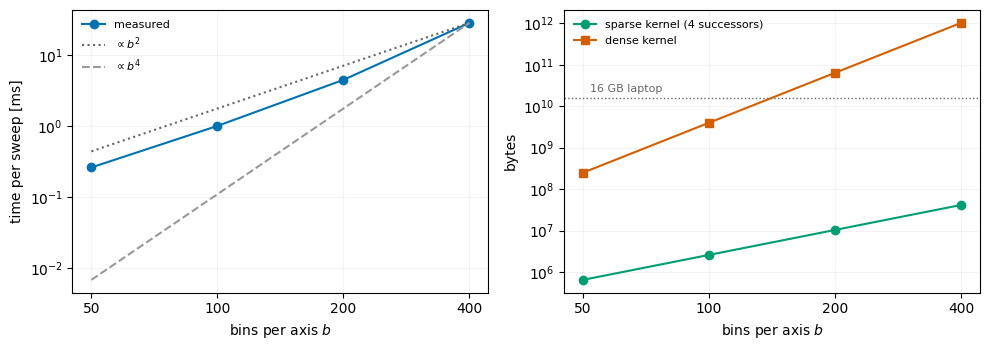

In [ ]:
B_LIST = (50, 100, 200, 400)
t_sweep, mem_sparse, mem_dense = [], [], []
for b in B_LIST:
    P_b, R_b = build_pendulum_mdp(b)
    V = np.zeros(b * b)
    t = time.perf_counter()
    for _ in range(20):
        V = pendulum_sweep(V, P_b, R_b)
    t_sweep.append((time.perf_counter() - t) / 20)
    mem_sparse.append(P_b.data.nbytes + P_b.indices.nbytes + P_b.indptr.nbytes)
    mem_dense.append(8.0 * (b * b) ** 2 * len(U_LEVELS))
t_sweep, mem_sparse, mem_dense = map(np.array, (t_sweep, mem_sparse, mem_dense))

slope = np.polyfit(np.log(B_LIST[1:]), np.log(t_sweep[1:]), 1)[0]
print(f"{'b':>5} {'|X|':>9} {'sweep [ms]':>11} {'sparse kernel':>14} {'dense kernel':>13}")
for b, ts, ms, md in zip(B_LIST, t_sweep, mem_sparse, mem_dense):
    print(f"{b:5d} {b * b:9d} {1e3 * ts:11.2f} {ms / 1e6:11.1f} MB {md / 1e9:10.1f} GB")
print(f"\nfitted exponent of sweep time against b (b = 100 to 400): {slope:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.6))
bb = np.array(B_LIST, dtype=float)
axes[0].loglog(bb, 1e3 * t_sweep, "o-", color="#0072B2", label="measured")
axes[0].loglog(bb, 1e3 * t_sweep[-1] * (bb / bb[-1]) ** 2, ":", color="0.4", label=r"$\propto b^2$")
axes[0].loglog(bb, 1e3 * t_sweep[-1] * (bb / bb[-1]) ** 4, "--", color="0.6", label=r"$\propto b^4$")
axes[0].set_xlabel("bins per axis $b$")
axes[0].set_ylabel("time per sweep [ms]")
axes[0].legend(frameon=False, fontsize=8)
axes[1].loglog(bb, mem_sparse, "o-", color="#009E73", label="sparse kernel (4 successors)")
axes[1].loglog(bb, mem_dense, "s-", color="#D55E00", label="dense kernel")
axes[1].axhline(16e9, color="0.4", ls=":", lw=1.0)
axes[1].text(52, 2.2e10, "16 GB laptop", color="0.4", fontsize=8)
axes[1].set_xlabel("bins per axis $b$")
axes[1].set_ylabel("bytes")
axes[1].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.set_xticks(B_LIST)
    ax.set_xticklabels([str(b) for b in B_LIST])
    ax.minorticks_off()
    ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

### Checkpoint 5

What exponent did your fit of sweep time against $b$ return, and why is it close to $d = 2$ rather
than the $2d = 4$ that the dense count $|\mathcal{X}|^2 |\mathcal{U}|$ predicts? How much memory
would the dense kernel need at $b = 400$?

### Answer: Checkpoint 5

* **Fitted Exponent:** The fitted exponent is **2.41**.
* **Why it is close to $d=2$:** The transition matrix is highly sparse. Due to bilinear interpolation, each state-action transition has at most **4 non-zero successor states**, regardless of the grid resolution $b$. Therefore, computing a sparse matrix-vector multiplication scales as $O(|\mathcal{X}| |\mathcal{U}|) = O(b^2 |\mathcal{U}|)$, which is much closer to $b^2$ ($d=2$) than the dense multiplication limit of $O(|\mathcal{X}|^2 |\mathcal{U}|) = O(b^4 |\mathcal{U}|)$ ($2d=4$).
* **Dense memory at $b=400$:** The dense representation would require **1024 GB (1 TB)** of memory, whereas the sparse representation requires only **41.6 MB**.

### (b) The swing-up, solved

Value iteration to a residual of $10^{-6}$ on the finest grid, 160 000 states. About ten seconds.
The controller is the greedy policy of the notes. At the measured continuous state it tries each
of the five inputs, looks one step ahead through the true dynamics, reads $V$ there by the same
bilinear interpolation, and applies the best. Nothing else is stored.

b = 400: 576 sweeps, 11.9 s
from hanging at rest: within 0.1 rad of upright after 2.60 s, final error 0.015 rad
distinct grid cells on the trajectory: 69 of 160000 (0.04 %)


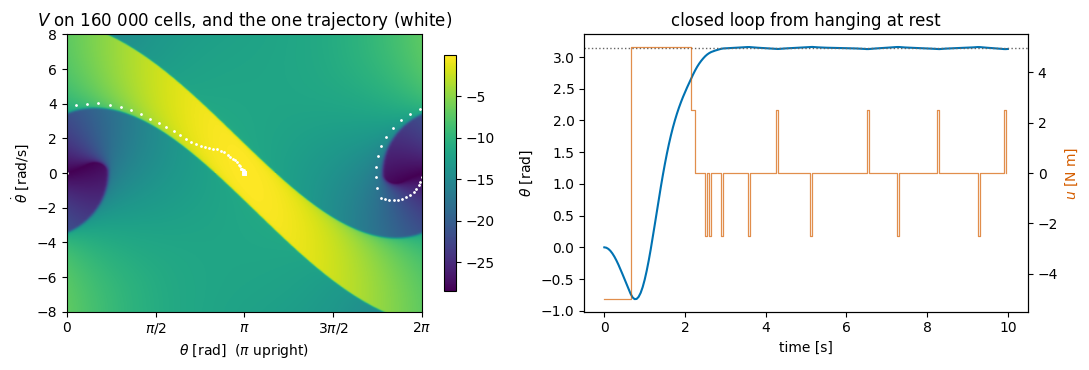

In [ ]:
B_FINE = 400
P_f, R_f = build_pendulum_mdp(B_FINE)
t = time.perf_counter()
V_pend, n_sw = pendulum_vi(P_f, R_f)
print(f"b = {B_FINE}: {n_sw} sweeps, {time.perf_counter() - t:.1f} s")


def V_at(th, om):
    idx, w = interp(th, om, B_FINE)
    return np.sum(V_pend[idx] * w, axis=-1)


def greedy_input(th, om):
    q = [reward(th, om, u) + GAMMA_PEND * V_at(*rk4_step(th, om, u)) for u in U_LEVELS]
    return U_LEVELS[int(np.argmax(q))]


T_SIM = 10.0
th, om, traj = 0.0, 0.0, []
for _ in range(int(T_SIM / DT)):
    u = greedy_input(th, om)
    traj.append((th, om, u))
    th, om = rk4_step(th, om, u)
traj.append((th, om, 0.0))
traj = np.array(traj)
err_up = np.abs(wrap(traj[:, 0] - np.pi))
t_up = DT * int(np.argmax(err_up < 0.1))

# The cells the closed loop actually passed through, nearest grid point per step.
th_ax, om_ax = grid_axes(B_FINE)
i_near = np.round(np.mod(traj[:, 0], 2 * np.pi) / (2 * np.pi / B_FINE)).astype(int) % B_FINE
j_near = np.round((np.clip(traj[:, 1], -OM_MAX, OM_MAX) + OM_MAX) / (2 * OM_MAX / (B_FINE - 1)))
n_visited = len(set(zip(i_near, j_near.astype(int))))
print(f"from hanging at rest: within 0.1 rad of upright after {t_up:.2f} s, "
      f"final error {err_up[-1]:.3f} rad")
print(f"distinct grid cells on the trajectory: {n_visited} of {B_FINE**2} "
      f"({100 * n_visited / B_FINE**2:.2f} %)")

fig, axes = plt.subplots(1, 2, figsize=(11.0, 3.8))
im = axes[0].imshow(V_pend.reshape(B_FINE, B_FINE).T, origin="lower", aspect="auto",
                    extent=[0, 2 * np.pi, -OM_MAX, OM_MAX], cmap="viridis")
axes[0].plot(np.mod(traj[:, 0], 2 * np.pi), traj[:, 1], ".", color="w", ms=2)
axes[0].set_xticks(np.pi * np.array([0, 0.5, 1, 1.5, 2]))
axes[0].set_xticklabels(["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"])
axes[0].set_xlabel(r"$\theta$ [rad]  ($\pi$ upright)")
axes[0].set_ylabel(r"$\dot\theta$ [rad/s]")
axes[0].set_title(r"$V$ on 160 000 cells, and the one trajectory (white)")
plt.colorbar(im, ax=axes[0], shrink=0.85)
tt = DT * np.arange(len(traj))
axes[1].plot(tt, traj[:, 0], color="#0072B2", label=r"$\theta$")
axes[1].axhline(np.pi, color="0.4", ls=":", lw=1.0)
axes[1].set_ylabel(r"$\theta$ [rad]")
axes[1].set_xlabel("time [s]")
ax2 = axes[1].twinx()
ax2.step(tt[:-1], traj[:-1, 2], where="post", color="#D55E00", lw=0.9, alpha=0.7)
ax2.set_ylabel("$u$ [N m]", color="#D55E00")
axes[1].set_title("closed loop from hanging at rest")
plt.tight_layout()
plt.show()

### Checkpoint 6

Does the greedy policy swing the pendulum up from hanging at rest, and what fraction of the
160 000 cells did the closed-loop trajectory pass through? Which controller from Week 2 evaluates
the value only along the trajectory it is on?

### Answer: Checkpoint 6

* **Swing-up:** Yes, the greedy policy successfully swings the pendulum up, reaching within 0.1 rad of upright after **2.60 seconds**.
* **Visited Fraction:** The trajectory visits only **69 out of 160,000 cells (0.04%)**.
* **Week 2 Controller:** The **Model Predictive Control (MPC)** / trajectory optimization controller from Week 2 only evaluates state values along the trajectory it is currently planning on, instead of solving the entire state space beforehand.

### (c) The same code on the robots of the course

This cell extrapolates and runs nothing heavy. The per-successor cost comes from your $b = 400$ timing. A sweep
touches $|\mathcal{X}|\,|\mathcal{U}|\,2^d$ kernel entries, because multilinear interpolation in
$d$ dimensions has $2^d$ corners. Value iteration needs about as many sweeps as it just did.

In [ ]:
c_entry = t_sweep[-1] / (B_FINE**2 * len(U_LEVELS) * 4)
AGE_OF_UNIVERSE = 4.4e17        # seconds
print(f"measured cost per kernel entry: {1e9 * c_entry:.1f} ns\n")
print(f"{'system':>12} {'d':>3} {'|X| at b=100':>13} {'|U|':>5} {'one sweep':>14} "
      f"{'all sweeps':>14} {'sparse kernel':>15}")
for name, d, nU in (("pendulum", 2, 5), ("cart-pole", 4, 5), ("7-DoF arm", 14, 10)):
    nX = 100.0**d
    entries = nX * nU * 2**d
    t1 = entries * c_entry
    print(f"{name:>12} {d:3d} {nX:13.0e} {nU:5d} {t1:12.2e} s {n_sw * t1:12.2e} s "
          f"{12 * entries / 1e9:12.2e} GB")
print(f"\nage of the universe: {AGE_OF_UNIVERSE:.1e} s")

The cart-pole is hours of compute and a kernel of order $10^2$ GB, painful and just about
possible. The arm's single sweep exceeds the age of the universe by several orders of magnitude,
with the sparse kernel, before any dense storage enters. That is the number the notes promised in
section 6.2, reached here from a timing you measured.

## 8. Analysis

A few sentences each. They are not quizzed, and they come back in the Week 4 session.

1. In the three panels of section 6(b), the true policy loss reaches zero within a few dozen
   sweeps at every $\gamma$, while the policy-loss bound grows like $1/(1-\gamma)^2$. If you had
   to stop value iteration on a real problem, what would you monitor, and what guarantee would you
   be giving up?

2. Policy iteration took six evaluations on the gridworld and value iteration 598 sweeps. Each
   evaluation is a dense $25 \times 25$ solve. Repeat the comparison in your head for the
   $b = 400$ pendulum, where one solve is a $160\,000 \times 160\,000$ system. Which algorithm would
   you run there, and what does modified policy iteration (notes section 5.2) let you trade?

3. The pendulum is nonlinear and saturated, and tabular DP solved it in seconds. A quadrotor near
   hover is almost linear, and the extrapolation of section 7(c) says tabular DP cannot touch it.
   Which property of a control problem predicts whether dynamic programming on a grid is
   applicable?